In [16]:
%load_ext autoreload
%autoreload 2

In [2]:
import pickle

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from quartz.data import Grid, pki_grid_scale, set_weights, weight_scale
from quartz.dataprocessing import (
    kmeans_clustering,
    grid_stddev,
    pair_overlap,
    dice_coefficient,
    calculate_pki_avg,
)
from quartz.grids import to_dxgrid


def pair_overlap_arrays(reference, targets):
    scores = []
    ref_grid = reference.astype(np.float64)

    for t in targets:
        np_grid = t.astype(np.float64)

        total_diff = np.sum(np.abs(np_grid - ref_grid))
        total_sum = np.sum(np.abs(np_grid)) + np.sum(np.abs(ref_grid))

        if total_sum == 0 or np.isinf(total_sum):
            scores.append(np.nan)
        else:
            scores.append(np.round(1 - (total_diff / total_sum), 4))

    return scores


def dice_coefficient_(reference, targets):
    dice_coefs = []
    for t in targets:
        top = 2 * np.sum(reference * t)
        bottom = np.sum(reference**2) + np.sum(t**2)
        if bottom == 0:
            dice_coefs.append(np.nan)
        else:
            dice_coefs.append(np.round(top / bottom, 4))

    # print("Dice coefficients:", dice_coefs)
    return dice_coefs

In [3]:
nclusters = 5
props = ["polarizability", "effectiveV", "RESP"]

# KMeans

In [4]:
grids: list[Grid] = pickle.load(open("grids.pkl", "rb"))
# actives = [g for g in grids if g.pki > 6]
actives = [g for g in grids if not np.isnan(g.pki)]
set_weights(actives, "pki")
print(len(actives))
pki_scaled_grids = [pki_grid_scale(grid) for grid in actives]

km_clusters = kmeans_clustering(
    [x for x in pki_scaled_grids if x is not None], props=props, n_clusters=nclusters
)

923


In [ ]:
pkis = [g.pki for g in actives]
pkis

In [5]:
print("Calculating pKi average")
pki_avg = calculate_pki_avg(pki_scaled_grids, props=props)
print("Calculating standard deviation")
stdev = grid_stddev(pki_scaled_grids, props=props, means=pki_avg, n_contribs=50)

Calculating pKi average


Calculating standard deviation


/scistor/gt/vie876/proj_FXa_QM/quartz/.pixi/envs/default/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


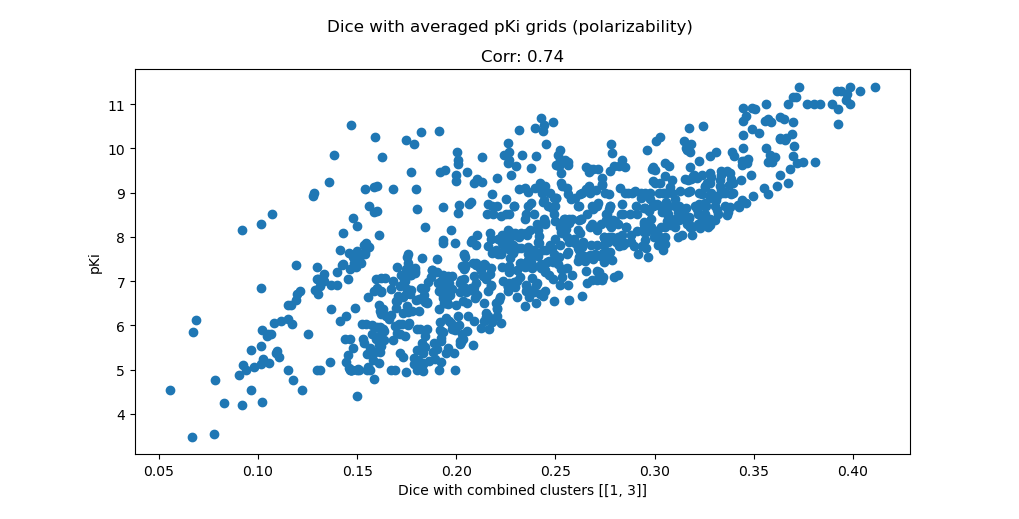

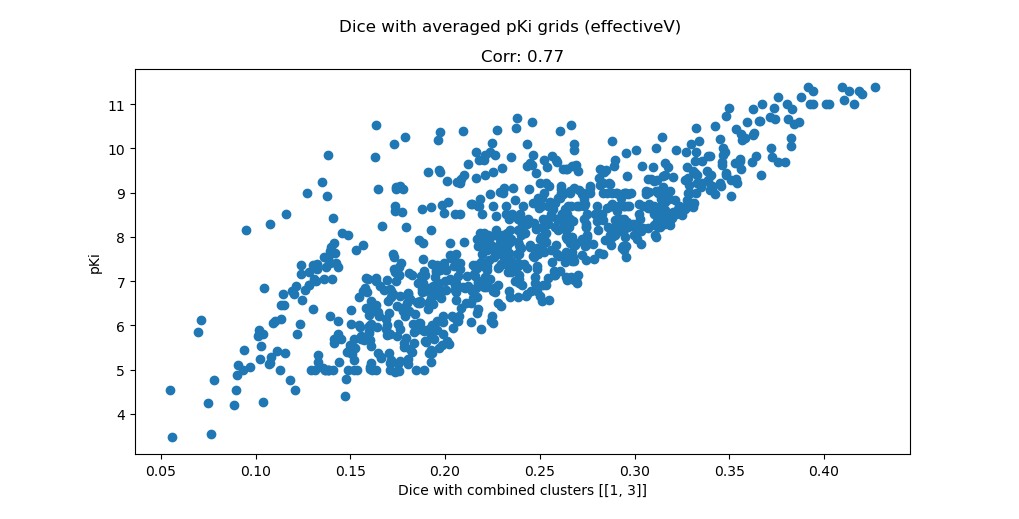

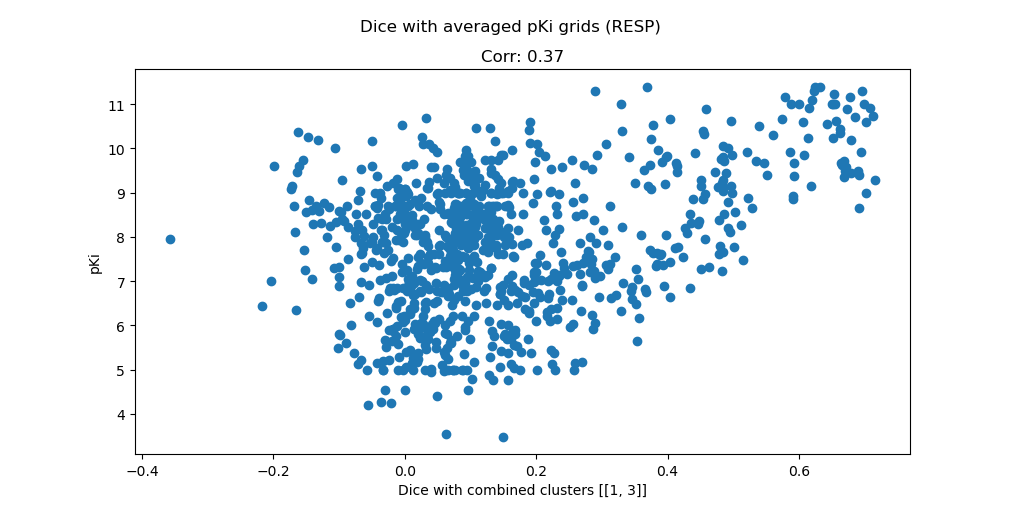

In [11]:
# condenses into the first cluster in a pair. [[1, 3]] -> 3 condenses into 1

selected_cluster = 1
condensed_clusters = {}
pairs_to_combine = [[1, 3]]
for key in props:
    overlap_per_cluster: dict[str, list[float]] = {}
    # condensed_clusters[key] = km_clusters.npGrid[key]
    labels = km_clusters.npGrid[key]
    for pair in pairs_to_combine:
        a, b = pair
        labels[labels == b] = a
    condensed_clusters[key] = labels
    indices = labels == selected_cluster
    masked_grids = [g.npGrid[key][indices] for g in pki_scaled_grids]
    masekd_grids_obj = [
        Grid(npGrid={key: m}, grid_props=g.grid_props)
        for g, m in zip(pki_scaled_grids, masked_grids)
    ]
    pki_prop = pki_avg.npGrid[key]
    masked_pki = pki_prop[indices]
    masked_pki_obj = Grid(
        npGrid={key: masked_pki}, grid_props=pki_scaled_grids[0].grid_props
    )
    masked_pki_grid = np.zeros_like(pki_prop)
    masked_pki_grid[indices] = masked_pki
    pki_dices = dice_coefficient(masked_pki_obj, masekd_grids_obj)
    overlap_per_cluster[f"pki_dice_{selected_cluster}"] = list(pki_dices[key].values())

    df = pd.DataFrame(overlap_per_cluster)
    df["pKi"] = [g.pki for g in pki_scaled_grids]
    df["code"] = [g.mol_data.pdb_code for g in pki_scaled_grids]
    df.dropna(inplace=True)

    pki_cols = [col for col in df.columns if col.startswith("pki_dice_")]
    n_clusters = len(pki_cols)

    n_cols = 1
    n_rows = max(1, (n_clusters + n_cols - 1) // n_cols)

    fig = plt.figure(figsize=(10 * n_cols, 5 * n_rows))
    subfigs = fig.subfigures(1, 2, wspace=0.1)
    fig.suptitle(f"Dice with averaged pKi grids ({key})")
    axs_pki = fig.subplots(n_rows, n_cols)
    axs_pki_flat = np.atleast_1d(axs_pki).flatten()

    # Plot pKi
    for idx, cluster_col in enumerate(pki_cols):
        axs_pki_flat[idx].scatter(df[cluster_col], df["pKi"], color="tab:blue")
        axs_pki_flat[idx].set_xlabel(f"Dice with combined clusters {pairs_to_combine}")
        axs_pki_flat[idx].set_ylabel("pKi")
        axs_pki_flat[idx].set_title(f"Corr: {df[cluster_col].corr(df['pKi']).round(2)}")

    for idx in range(n_clusters, len(axs_pki_flat)):
        axs_pki_flat[idx].set_visible(False)

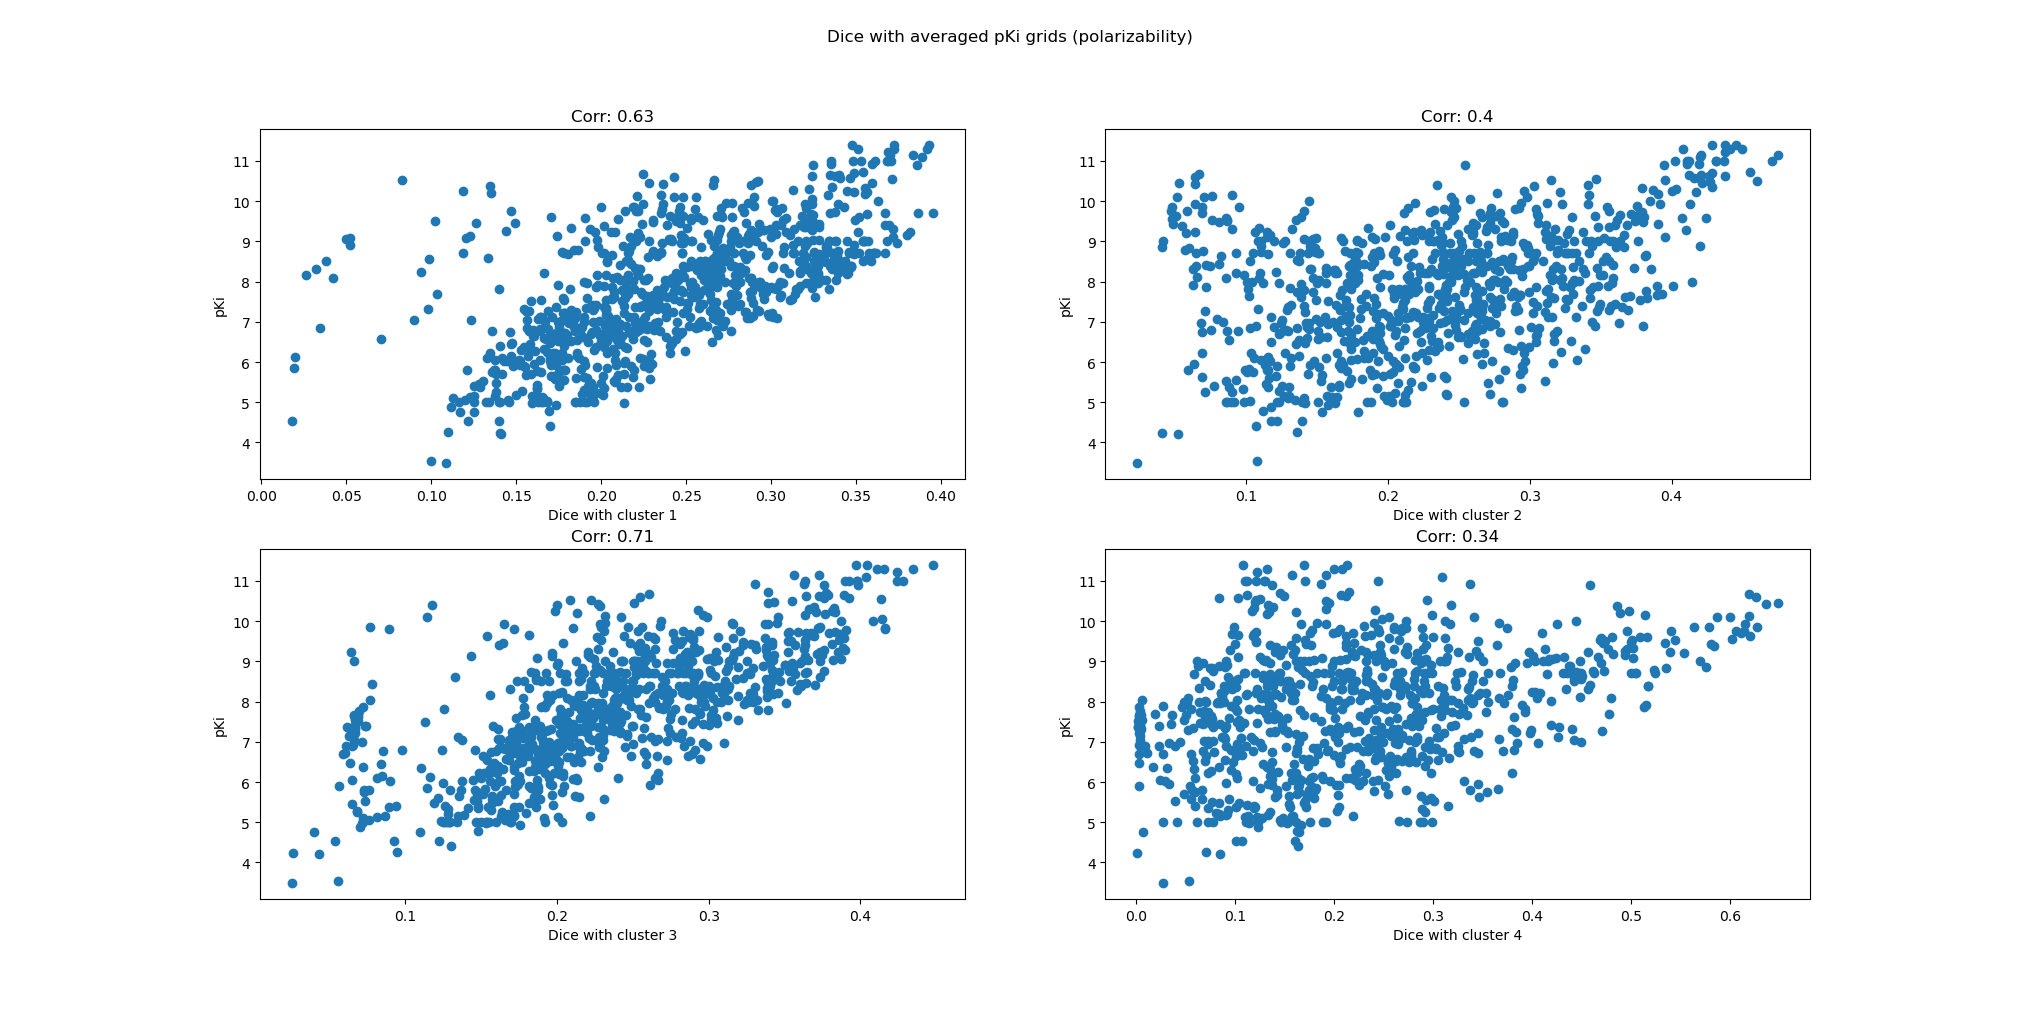

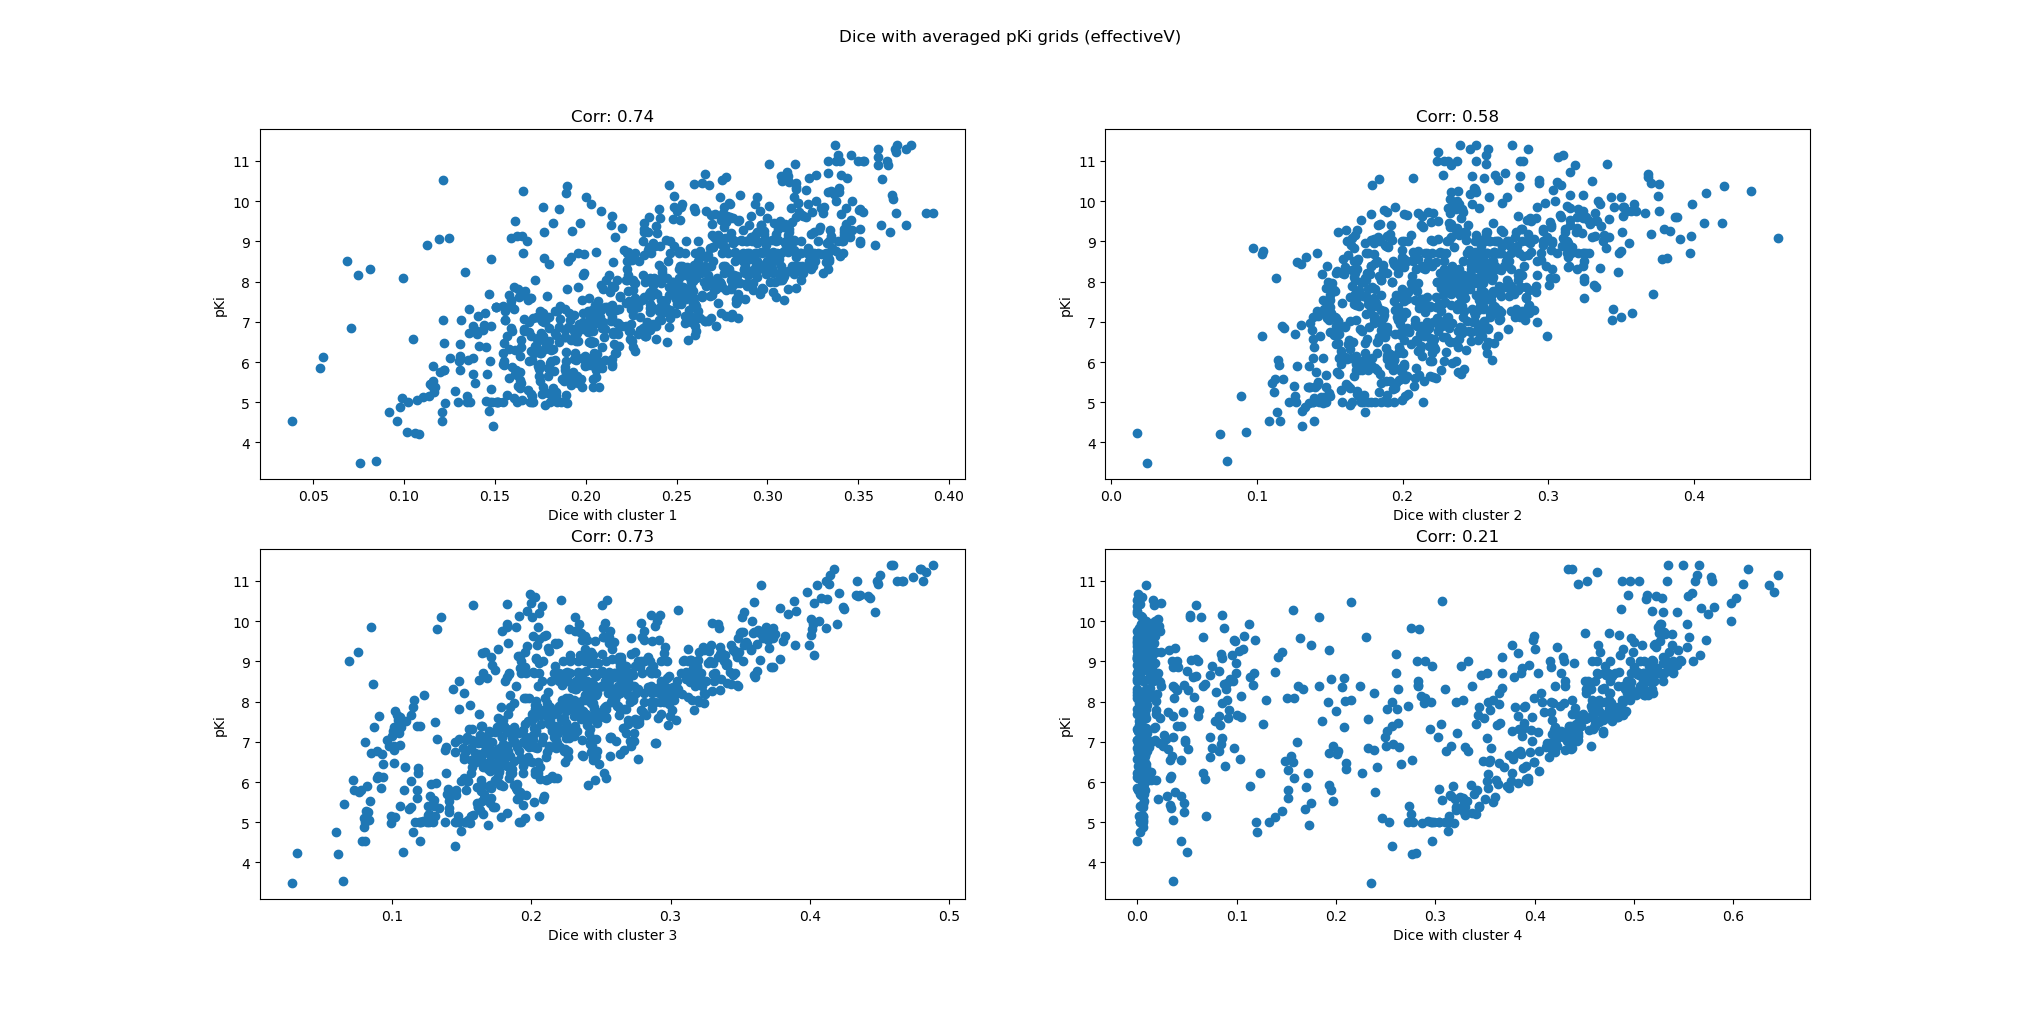

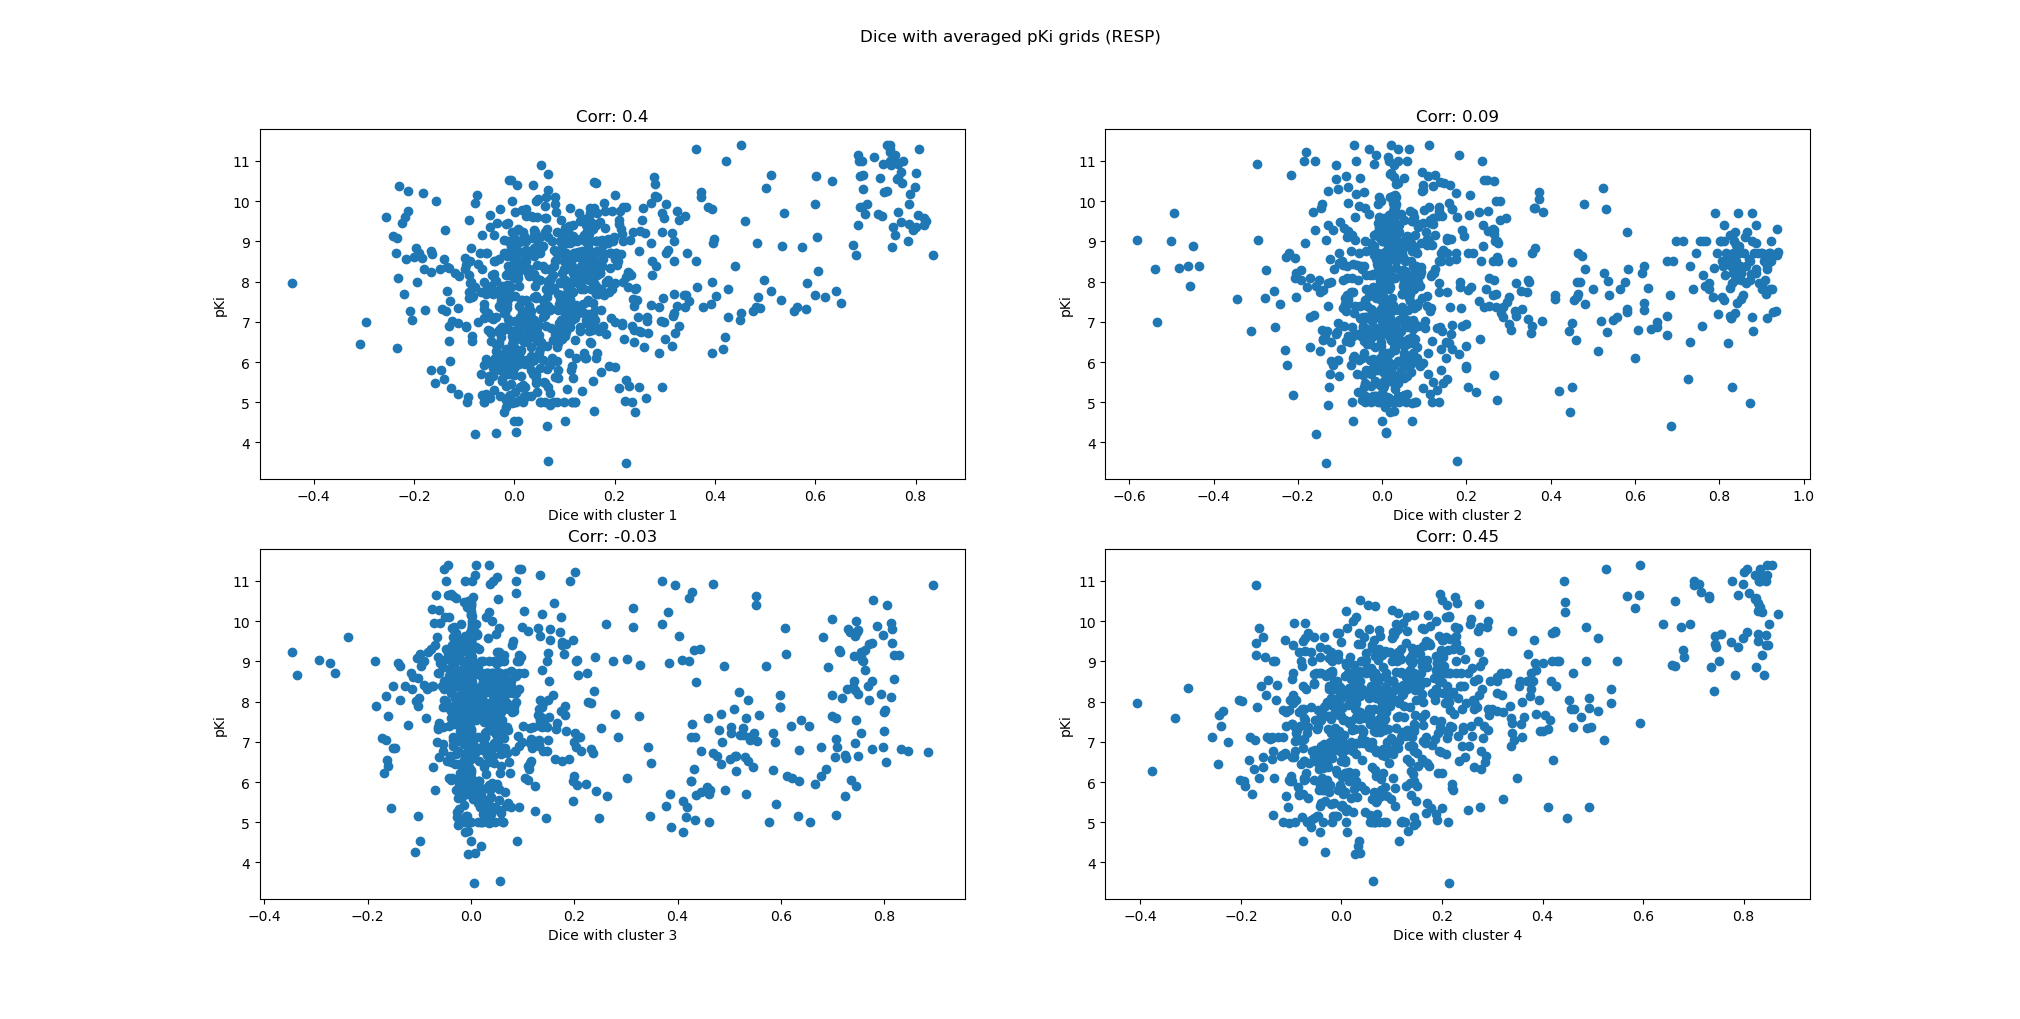

In [ ]:
for key in props:
    overlap_per_cluster: dict[str, list[float]] = {}
    labels_flat = km_clusters.npGrid[key]
    for i in range(1, np.max(km_clusters.npGrid[key]) + 1):
        # print(f"Processing cluster {i}")
        indices = labels_flat == i
        masked_grids = [g.npGrid[key][indices] for g in pki_scaled_grids]
        masekd_grids_obj = [
            Grid(npGrid={key: m}, grid_props=g.grid_props)
            for g, m in zip(pki_scaled_grids, masked_grids)
        ]

        # print(masked_grids[0].shape)

        # stdev_prop = stdev.npGrid[key]
        # masked_std = stdev_prop[indices]
        # masked_std_obj = Grid(npGrid={key: masked_std}, grid_props=pki_scaled_grids[0].grid_props)

        pki_prop = pki_avg.npGrid[key]
        masked_pki = pki_prop[indices]
        masked_pki_obj = Grid(
            npGrid={key: masked_pki}, grid_props=pki_scaled_grids[0].grid_props
        )

        # Save masked pki to dx
        masked_pki_grid = np.zeros_like(pki_prop)
        masked_pki_grid[indices] = masked_pki
        # to_dxgrid(masked_pki_grid, filename="pki_cluster_" + str(i) + ".dx", origin=grids[0].grid_props["origin"], spacing=grids[0].grid_props["size"])

        # Save masked stdev to dx
        # masked_std_grid = np.zeros_like(stdev_prop)
        # masked_std_grid[indices] = masked_std
        # print(masked_std_grid.shape)
        # to_dxgrid(masked_std_grid, filename="std_cluster_" + str(i) + ".dx", origin=grids[0].grid_props["origin"], spacing=grids[0].grid_props["size"])

        if not masked_grids:
            continue

        # sd_dices = dice_coefficient(masked_std_obj, masekd_grids_obj)
        pki_dices = dice_coefficient(masked_pki_obj, masekd_grids_obj)

        # overlap_per_cluster[f"sd_dice_{i}"] = list(sd_dices[key].values())
        overlap_per_cluster[f"pki_dice_{i}"] = list(pki_dices[key].values())

    df = pd.DataFrame(overlap_per_cluster)
    df["pKi"] = [g.pki for g in pki_scaled_grids]
    df["code"] = [g.mol_data.pdb_code for g in pki_scaled_grids]
    df.dropna(inplace=True)

    # sd_cols = [col for col in df.columns if col.startswith("sd_dice_")]
    pki_cols = [col for col in df.columns if col.startswith("pki_dice_")]
    n_clusters = len(pki_cols)

    n_cols = 2
    n_rows = max(1, (n_clusters + n_cols - 1) // n_cols)

    fig = plt.figure(figsize=(10 * n_cols, 5 * n_rows))
    subfigs = fig.subfigures(1, 2, wspace=0.1)

    # subfigs[0].suptitle(f"Dice with averaged pKi grids ({key})")
    fig.suptitle(f"Dice with averaged pKi grids ({key})")
    # subfigs[1].suptitle(f"Dice with SD grids ({key})")

    # axs_pki = subfigs[0].subplots(n_rows, n_cols)
    axs_pki = fig.subplots(n_rows, n_cols)
    # axs_sd = subfigs[1].subplots(n_rows, n_cols)

    axs_pki_flat = np.atleast_1d(axs_pki).flatten()
    # axs_sd_flat = np.atleast_1d(axs_sd).flatten()

    # Plot pKi
    for idx, cluster_col in enumerate(pki_cols):
        axs_pki_flat[idx].scatter(df[cluster_col], df["pKi"], color="tab:blue")
        axs_pki_flat[idx].set_xlabel(f"Dice with cluster {cluster_col.split('_')[-1]}")
        axs_pki_flat[idx].set_ylabel("pKi")
        axs_pki_flat[idx].set_title(f"Corr: {df[cluster_col].corr(df['pKi']).round(2)}")

    for idx in range(n_clusters, len(axs_pki_flat)):
        axs_pki_flat[idx].set_visible(False)

    # Plot SD
    # for idx, cluster_col in enumerate(sd_cols):
    #     axs_sd_flat[idx].scatter(df[cluster_col], df["pKi"], color='tab:orange')
    #     axs_sd_flat[idx].set_xlabel(f"Dice with cluster {cluster_col.split('_')[-1]}")
    #     axs_sd_flat[idx].set_ylabel("pKi")
    #     axs_sd_flat[idx].set_title(f"Corr: {df[cluster_col].corr(df['pKi']).round(2)}")

    # for idx in range(n_clusters, len(axs_sd_flat)):
    #     axs_sd_flat[idx].set_visible(False)

    # plt.tight_layout()
    plt.show()

In [11]:
# Control which clusters to plot (exclude cluster 0 by default)
clusters_to_plot = [
    1,
    2,
    3,
    4,
    5,
]  # Modify this list to control which clusters are displayed

# Get cluster labels (3D grid shape)
labels = km_clusters.npGrid["polarizability"]

# Generate grid coordinates based on the shape of the cluster data
shape = labels.shape
x_coords, y_coords, z_coords = np.meshgrid(
    np.arange(shape[0]), np.arange(shape[1]), np.arange(shape[2]), indexing="ij"
)

# Flatten all arrays for plotting
x_flat = x_coords.flatten()
y_flat = y_coords.flatten()
z_flat = z_coords.flatten()
labels_flat = labels.flatten()

# Filter to only include selected clusters
mask = np.isin(labels_flat, clusters_to_plot)
x_filtered = x_flat[mask]
y_filtered = y_flat[mask]
z_filtered = z_flat[mask]
labels_filtered = labels_flat[mask]

# Create a plotly 3D scatter plot with discrete colors for clusters
fig = px.scatter_3d(
    x=x_filtered,
    y=y_filtered,
    z=z_filtered,
    color=labels_filtered.astype(str),  # Convert to string for discrete colors
    title="K-Means Clustering of Grid Points",
    labels={"x": "X", "y": "Y", "z": "Z", "color": "Cluster"},
    opacity=0.6,
)
fig.update_traces(marker=dict(size=2))
fig.update_layout(legend_title_text="Cluster")
fig.show()

# Linear regression

In [ ]:
for i in range(0, np.max(km_clusters.npGrid["RESP"]) + 1):
    plt.hist(df.iloc[:, i])
    plt.show()

Mean squared error: 1.56
Coefficient of determination: 0.29


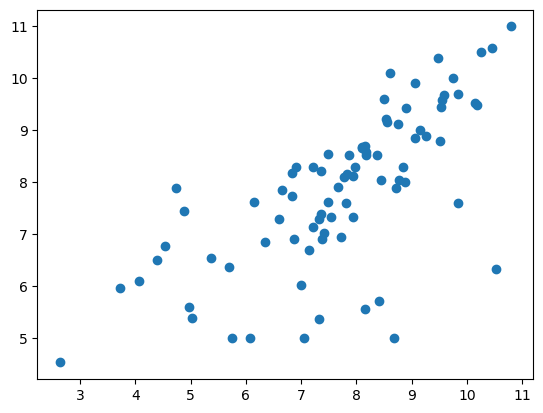

In [ ]:
from sklearn import linear_model
from sklearn import gaussian_process
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.svm import SVR

from sklearn.preprocessing import PowerTransformer


X = np.abs(df[cluster_cols].values + 1e-8)
bc = PowerTransformer(method="box-cox")
X_bc = bc.fit_transform(X)

y = df["pKi"].values
X_train, X_test, y_train, y_test = train_test_split(
    X_bc, y, test_size=0.2, random_state=2137
)
# reg = linear_model.LinearRegression().fit(X_train, y_train)
reg = gaussian_process.GaussianProcessRegressor().fit(X_train, y_train)
y_pred = reg.predict(X_test)
print(f"Mean squared error: {mean_squared_error(y_test, y_pred):.2f}")
print(f"Coefficient of determination: {r2_score(y_test, y_pred):.2f}")
plt.scatter(y_pred, y_test)


Cluster 0 Support Vector Regression Results:
Mean squared error: 2.96
Coefficient of determination: -0.02


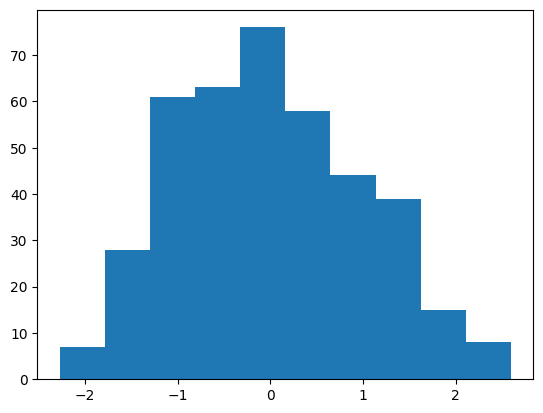

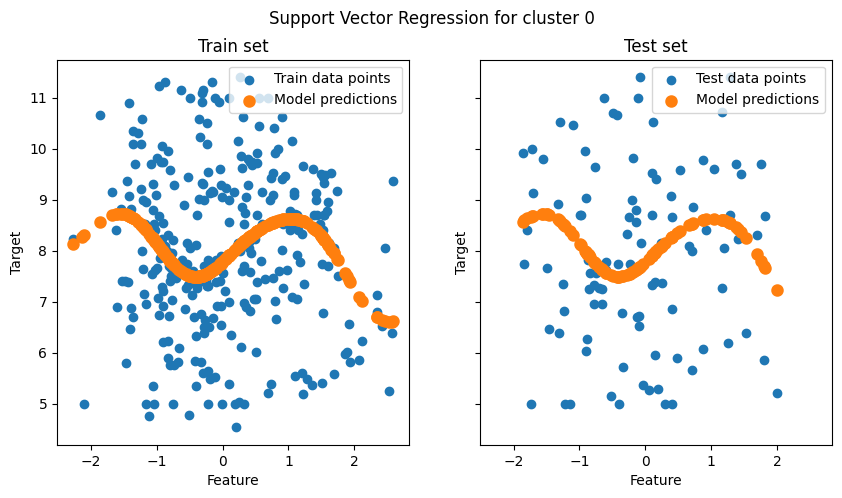

Cluster 1 Support Vector Regression Results:
Mean squared error: 2.37
Coefficient of determination: 0.18


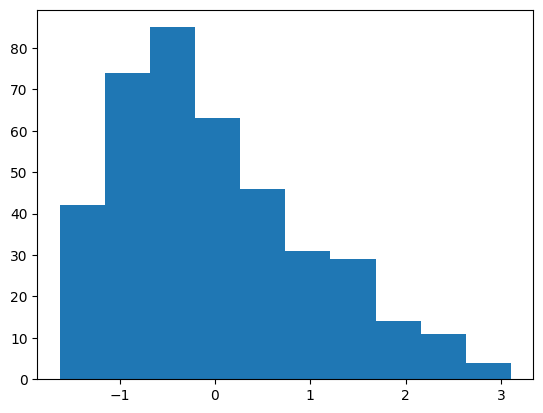

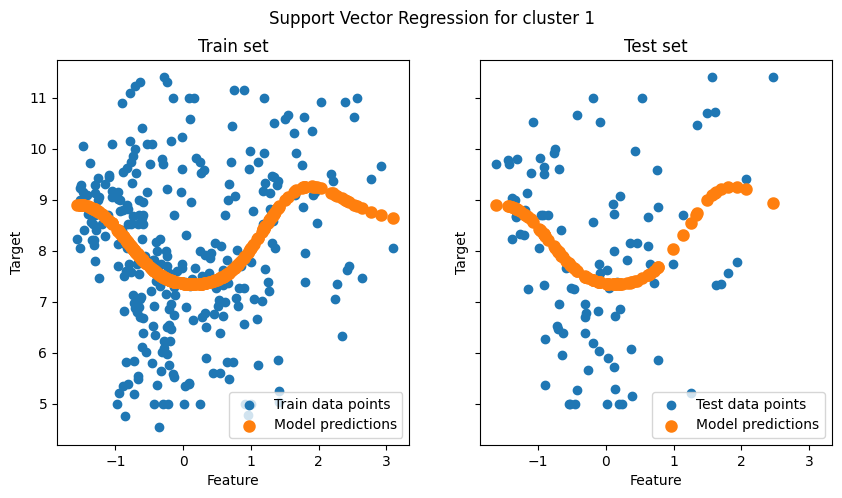

Cluster 2 Support Vector Regression Results:
Mean squared error: 2.77
Coefficient of determination: 0.04


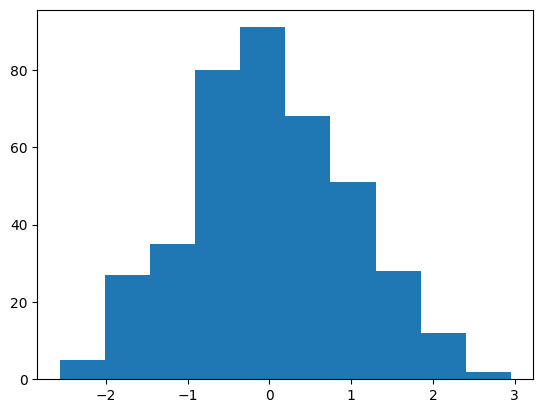

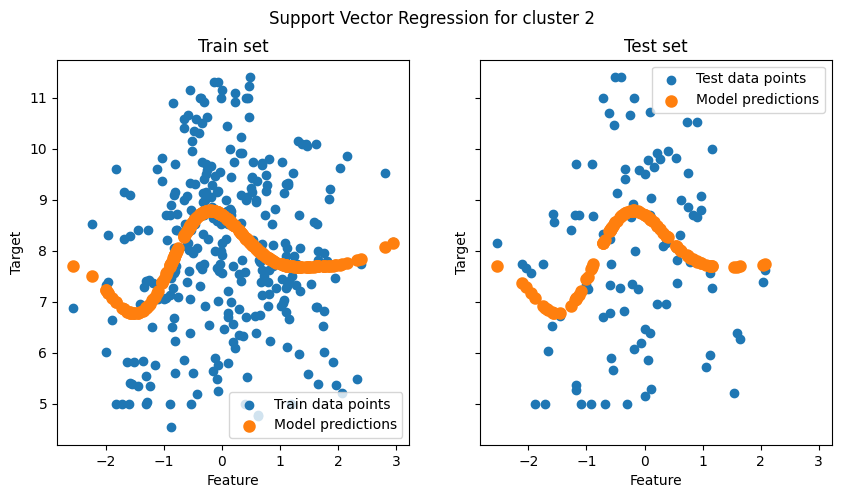

Cluster 3 Support Vector Regression Results:
Mean squared error: 2.08
Coefficient of determination: 0.28


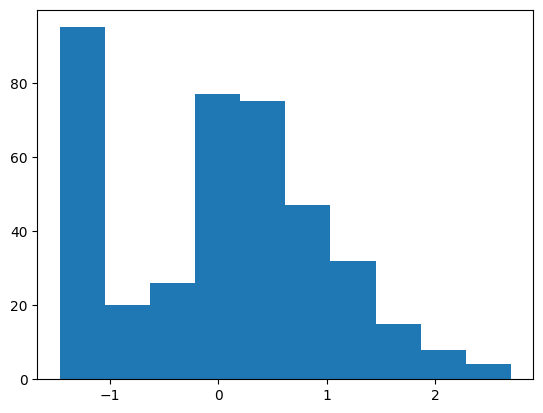

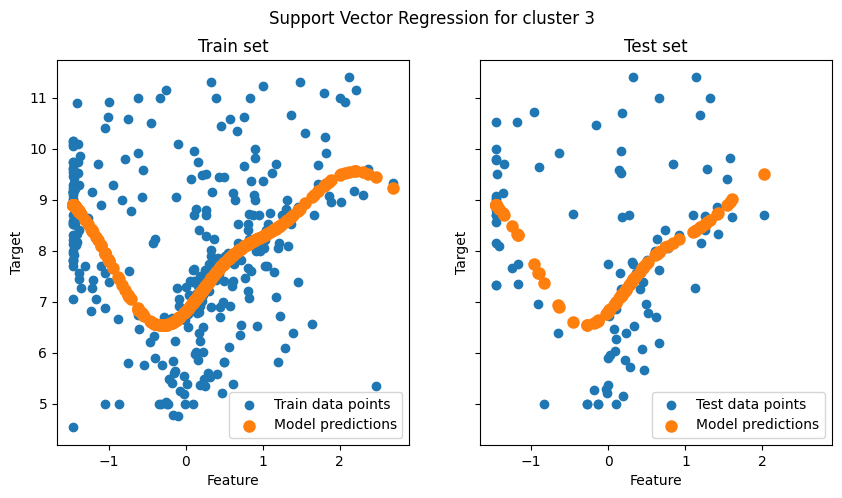

Cluster 4 Support Vector Regression Results:
Mean squared error: 2.46
Coefficient of determination: 0.15


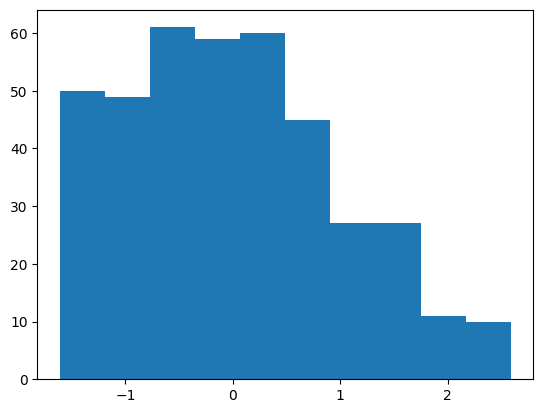

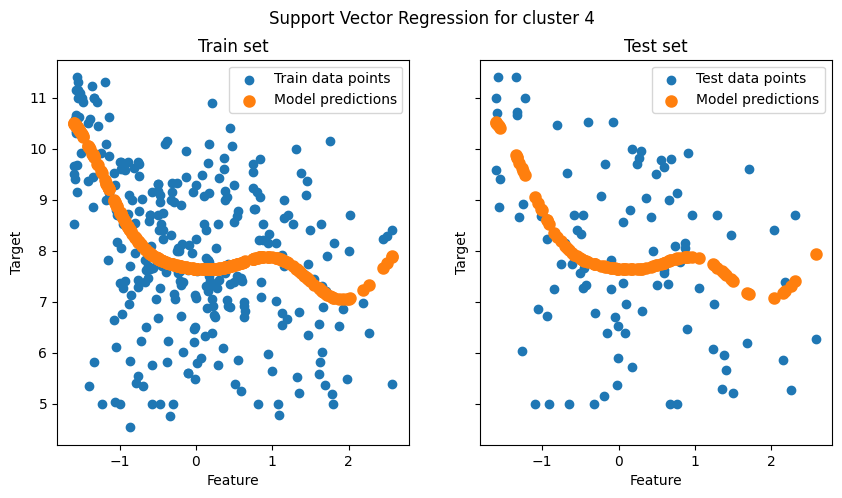

In [ ]:
import matplotlib.pyplot as plt
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler

for i in range(0, np.max(km_clusters.npGrid["RESP"]) + 1):
    print(f"Cluster {i} Support Vector Regression Results:")

    X = pd.DataFrame(
        preprocessing.StandardScaler().fit_transform(df.iloc[:, i : i + 1])
    )
    plt.hist(X)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=2137
    )

    reg = SVR(kernel="rbf").fit(X_train, y_train)  # noqa: F821
    y_pred = reg.predict(X_test)

    print(f"Mean squared error: {mean_squared_error(y_test, y_pred):.2f}")
    print(f"Coefficient of determination: {r2_score(y_test, y_pred):.2f}")

    fig, ax = plt.subplots(ncols=2, figsize=(10, 5), sharex=True, sharey=True)
    ax[0].scatter(X_train.iloc[:, 0], y_train, label="Train data points")
    ax[0].scatter(
        X_train.iloc[:, 0],
        reg.predict(X_train),
        linewidth=3,
        color="tab:orange",
        label="Model predictions",
    )
    ax[0].set(xlabel="Feature", ylabel="Target", title="Train set")
    ax[0].legend()

    ax[1].scatter(X_test.iloc[:, 0], y_test, label="Test data points")
    ax[1].scatter(
        X_test.iloc[:, 0],
        y_pred,
        linewidth=3,
        color="tab:orange",
        label="Model predictions",
    )
    ax[1].set(xlabel="Feature", ylabel="Target", title="Test set")
    ax[1].legend()

    fig.suptitle(f"Support Vector Regression for cluster {i}")

    plt.show()

In [107]:
test_3d_arr = np.round(np.random.randint(0, 20, size=(10, 5, 5, 5)))
n_mask = np.where(np.count_nonzero(test_3d_arr, axis=0) >= 10, True, False)

# Create output array with same values
out_arr = test_3d_arr.copy()

# Set non-masked voxels to zero across all grids
out_arr[:, ~n_mask] = 0

print(f"Original shape: {test_3d_arr.shape}")
print(f"Output shape: {out_arr.shape}")
print(f"Number of masked voxels: {np.sum(n_mask)}")
print(f"Number of non-zero elements in output: {np.count_nonzero(out_arr)}")
print(f"\nExample slice [0, :, :, 0]:")
print(f"Original:\n{test_3d_arr[0, :, :, 0]}")
print(f"Masked:\n{out_arr[0, :, :, 0]}")

Original shape: (10, 5, 5, 5)
Output shape: (10, 5, 5, 5)
Number of masked voxels: 74
Number of non-zero elements in output: 740

Example slice [0, :, :, 0]:
Original:
[[12  1 10  7 17]
 [ 4  9 17 13  1]
 [12  5 10  4 17]
 [12 14 18  5  0]
 [ 8  2  1  8  6]]
Masked:
[[12  1 10  0  0]
 [ 4  9  0 13  1]
 [ 0  0 10  4 17]
 [12 14  0  0  0]
 [ 8  2  0  8  0]]
